In [1]:
# Previously, we loaded the data in retrosheet and processed the data to get team level stats.
# This was saved in the file 'df_bp1.csv'
# This notebook will load the data and do some initial eda (exploratory analysis), then build and evaluate our first predictive model.
# Once again, this is based of work by @numeristical and I am learning from that youtube channel. Special thanks to them!

In [1]:
# Uncomment if you need to install any of the following packages
#%pip install lightgbm
#%pip install ml_insights --upgrade
#%pip install structureboost

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


  Using cached ml_insights-1.1.0-py3-none-any.whl.metadata (3.0 kB)
  Using cached scikit_learn-1.9.1-cp313-cp313-win_amd64.whl.metadata (9.3 kB)
  Using cached splinecalib-0.0.13.tar.gz (2.6 MB)
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached threadpoolctl-3.7.0-py3-none-any.whl.metadata (24 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
Using cached ml_insights-1.1.0-py3-none-any.whl (26 kB)
Using cached scikit_learn-1.9.1-cp313-cp313-win_amd64.whl (8.2 MB)
Using cached joblib-1.6.0-py3-none-any.whl (306 kB)
Using cached cloudpickle-3.1.2-py3-none-any.whl (22 kB)
Using cached threadpoolctl-3.7.0-py3-none-a

  error: subprocess-exited-with-error
  
  × Building wheel for splinecalib (pyproject.toml) did not run successfully.
  │ exit code: 1
  ╰─> [57 lines of output]
      running bdist_wheel
      running build
      running build_py
      creating build\lib.win-amd64-cpython-313\splinecalib
      copying splinecalib\calib_utils.py -> build\lib.win-amd64-cpython-313\splinecalib
      copying splinecalib\splinecalib.py -> build\lib.win-amd64-cpython-313\splinecalib
      copying splinecalib\__init__.py -> build\lib.win-amd64-cpython-313\splinecalib
      creating build\lib.win-amd64-cpython-313\splinecalib\tests
      copying splinecalib\tests\test_binary_datasets.py -> build\lib.win-amd64-cpython-313\splinecalib\tests
      copying splinecalib\tests\test_multiclass_datasets.py -> build\lib.win-amd64-cpython-313\splinecalib\tests
      copying splinecalib\tests\test_unity_prior.py -> build\lib.win-amd64-cpython-313\splinecalib\tests
      copying splinecalib\tests\__init__.py -> build\lib

  Using cached structureboost-0.7.0.tar.gz (1.9 MB)
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached ml_insights-1.1.0-py3-none-any.whl.metadata (3.0 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
  Using cached scikit_learn-1.9.1-cp313-cp313-win_amd64.whl.metadata (9.3 kB)
  Using cached splinecalib-0.0.13.tar.gz (2.6 MB)
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproj

  error: subprocess-exited-with-error
  
  × Building wheel for structureboost (pyproject.toml) did not run successfully.
  │ exit code: 1
  ╰─> [69 lines of output]
      running bdist_wheel
      running build
      running build_py
      creating build\lib.win-amd64-cpython-313\structureboost
      copying structureboost\utils.py -> build\lib.win-amd64-cpython-313\structureboost
      copying structureboost\__init__.py -> build\lib.win-amd64-cpython-313\structureboost
      creating build\lib.win-amd64-cpython-313\structureboost\tests
      copying structureboost\tests\test_basics.py -> build\lib.win-amd64-cpython-313\structureboost\tests
      copying structureboost\tests\test_coarsage_1.py -> build\lib.win-amd64-cpython-313\structureboost\tests
      copying structureboost\tests\test_dt.py -> build\lib.win-amd64-cpython-313\structureboost\tests
      copying structureboost\tests\test_gb.py -> build\lib.win-amd64-cpython-313\structureboost\tests
      copying structureboost\tests\t

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import lightgbm as lgbm
import structureboost as stb
import ml_insights as mli
from structureboost import log_loss
pd.set_option('display.max_columns', 1000)
pd.set_option('display.max_rows', 1000)

In [3]:
df=pd.read_csv('df_bp1.csv')

C:\Users\themi\AppData\Local\Temp\ipykernel_20112\3742704531.py:1: DtypeWarning: Columns (0: completion_info, 1: forfeit_info, 2: protest_info, 3: ump_LF_id, 4: ump_RF_id) have mixed types. Specify dtype option on import or set low_memory=False.
  df=pd.read_csv('df_bp1.csv')


**DATA CHECKS/ EXPLORATION**

In [4]:
df.info(max_cols=1000)

<class 'pandas.DataFrame'>
RangeIndex: 101135 entries, 0 to 101134
Data columns (total 194 columns):
 #    Column                Non-Null Count   Dtype  
---   ------                --------------   -----  
 0    date                  101135 non-null  int64  
 1    dblheader_code        101135 non-null  int64  
 2    day_of_week           101135 non-null  str    
 3    team_v                101135 non-null  str    
 4    league_v              101135 non-null  str    
 5    game_no_v             101135 non-null  int64  
 6    team_h                101135 non-null  str    
 7    league_h              101135 non-null  str    
 8    game_no_h             101135 non-null  int64  
 9    runs_v                101135 non-null  int64  
 10   runs_h                101135 non-null  int64  
 11   outs_total            101135 non-null  int64  
 12   day_night             101135 non-null  str    
 13   completion_info       92 non-null      str    
 14   forfeit_info          1 non-null       str   

In [5]:
df.season.value_counts().sort_index()
# Notice that some seasons have different rows? Some games are shortened (1981) due to strikes.
# The number sticks around 2100 until 1994 (another player strike).
# We then see a big jump from 2100 games to 2200 then to 2400 due to expansion waves.
# The expansion years were between 1961-1998.
# 2020 was a shortened season due to a pandemic.

season
1980    2105
1981    1394
1982    2107
1983    2109
1984    2105
1985    2103
1986    2103
1987    2105
1988    2100
1989    2106
1990    2105
1991    2104
1992    2106
1993    2269
1994    1600
1995    2017
1996    2267
1997    2266
1998    2432
1999    2428
2000    2429
2001    2429
2002    2426
2003    2430
2004    2428
2005    2431
2006    2429
2007    2431
2008    2428
2009    2430
2010    2430
2011    2429
2012    2430
2013    2431
2014    2430
2015    2429
2016    2428
2017    2430
2018    2431
2019    2429
2020     898
2021    2429
2022    2430
2023    2430
2024    2429
Name: count, dtype: int64

In [6]:
# Let's look at the home victory mean again
hv_mean = df.home_victory.mean()
hv_mean

np.float64(0.5375488208829782)

In [7]:
# When we look at the column home victory that was made, if run differential is x>0, home wins.
# But we did not check for rain delay games ie when run_df is not 0
df.run_diff.value_counts()
# 35 counts of zero but they are not actually losses.

run_diff
 1     17717
-1     11452
 2      9465
-2      9101
 3      7509
-3      7224
 4      5875
-4      5679
 5      4221
-5      4168
 6      3079
-6      2931
 7      2143
-7      2108
 8      1545
-8      1410
 9      1039
-9       963
 10      666
-10      652
 11      426
-11      389
 12      266
-12      242
-13      181
 13      176
 14       99
-14       95
 15       52
-15       49
-16       41
 16       36
 0        35
 17       22
-17       18
-18       13
 19       10
 18        9
-19        8
 21        6
-21        4
-20        3
 20        3
 22        1
-22        1
-27        1
-23        1
-24        1
Name: count, dtype: int64

In [10]:
df.outs_total.value_counts()

outs_total
51     45830
54     42201
60      2048
53      1921
52      1698
66      1054
58       946
59       857
72       560
57       467
64       452
65       427
78       304
70       256
63       225
71       218
84       163
77       136
42       125
76       125
39       120
69       115
82        77
83        74
90        73
75        70
89        46
96        46
36        33
30        33
48        29
81        28
45        24
102       23
33        23
88        23
94        20
95        19
41        18
108       17
31        17
40        12
100       11
87        11
101       10
46        10
93        10
43         9
106        8
28         8
114        8
38         8
34         7
44         7
27         7
37         7
47         6
32         6
105        6
120        5
29         4
49         4
113        4
111        4
118        3
50         3
107        3
35         2
132        2
112        2
126        1
79         1
148        1
131        1
129        1
55         1
9

60 outs means ten innings
52 or 53 means home team was losing into the ninth but won at the bottom of the ninth

In [8]:
# 9 innings should have 53 outs in wins.
# But we see 51 appearing more than 53.
# So usually it is because the home team is winning and the bottom of the ninth is not played.
df.home_victory[df.outs_total==53].mean()

np.float64(0.9994794377928162)

In [11]:
# Let's find the the games where outs are 53 and the run differential is not 1. The ':' is inclusive

df.loc[(df.outs_total==53) & (df.home_victory!=1),:]

,date,dblheader_code,day_of_week,team_v,league_v,game_no_v,team_h,league_h,game_no_h,runs_v,runs_h,outs_total,day_night,completion_info,forfeit_info,protest_info,ballpark_id,attendance,game_minutes,linescore_v,linescore_h,AB_v,H_v,2B_v,3B_v,HR_v,RBI_v,SH_v,SF_v,HBP_v,BB_v,IBB_v,SO_v,SB_v,CS_v,GIDP_v,CI_v,LOB_v,P_num_v,ERind_v,ERteam_v,WP_v,balk_v,PO_v,ASST_v,ERR_v,PB_v,DP_v,TP_v,AB_h,H_h,2B_h,3B_h,HR_h,RBI_h,SH_h,SF_h,HBP_h,BB_h,IBB_h,SO_h,SB_h,CS_h,GIDP_h,CI_h,LOB_h,P_num_h,ERind_h,ERteam_h,WP_h,balk_h,PO_h,ASST_h,ERR_h,PB_h,DP_h,TP_h,ump_HB_id,ump_HB_name,ump_1B_id,ump_1B_name,ump_2B_id,ump_2B_name,ump_3B_id,ump_3B_name,ump_LF_id,ump_LF_name,ump_RF_id,ump_RF_name,mgr_id_v,mgr_name_v,mgr_id_h,mgr_name_h,pitcher_id_w,pitcher_name_w,pitcher_id_l,pitcher_name_l,pitcher_id_s,pitcher_name_s,GWRBI_id,GWRBI_name,pitcher_start_id_v,pitcher_start_name_v,pitcher_start_id_h,pitcher_start_name_h,batter1_name_v,batter1_id_v,batter1_pos_v,batter2_name_v,batter2_id_v,batter2_pos_v,batter3_name_v,batter3_id_v,batter3_pos_v,batter4_name_v,batter4_id_v,batter4_pos_v,batter5_name_v,batter5_id_v,batter5_pos_v,batter6_name_v,batter6_id_v,batter6_pos_v,batter7_name_v,batter7_id_v,batter7_pos_v,batter8_name_v,batter8_id_v,batter8_pos_v,batter9_name_v,batter9_id_v,batter9_pos_v,batter1_name_h,batter1_id_h,batter1_pos_h,batter2_name_h,batter2_id_h,batter2_pos_h,batter3_name_h,batter3_id_h,batter3_pos_h,batter4_name_h,batter4_id_h,batter4_pos_h,batter5_name_h,batter5_id_h,batter5_pos_h,batter6_name_h,batter6_id_h,batter6_pos_h,batter7_name_h,batter7_id_h,batter7_pos_h,batter8_name_h,batter8_id_h,batter8_pos_h,batter9_name_h,batter9_id_h,batter9_pos_h,misc_info,acqui_info,season,run_diff,home_victory,run_total,date_dblhead,BATAVG_162_h,BATAVG_162_v,OBP_162_h,OBP_162_v,SLG_162_h,SLG_162_v,OBS_162_h,OBS_162_v,SB_162_h,SB_162_v,CS_162_h,CS_162_v,ERR_162_h,ERR_162_v,BATAVG_30_h,BATAVG_30_v,OBP_30_h,OBP_30_v,SLG_30_h,SLG_30_v,OBS_30_h,OBS_30_v,SB_30_h,SB_30_v,CS_30_h,CS_30_v,ERR_30_h,ERR_30_v
56258,20050915,0,Thu,SLN,NL,148,CHN,NL,147,6,1,53,N,NaN,NaN,NaN,CHI11,37849.0,167,300000030,000000001,33,9,1,0,0,5,0,1,0,5,0,6,0,1,1,0,6,2,1,1,1,0,26,12,1,0,1,0,33,8,0,0,1,1,0,0,0,2,0,8,0,0,1,0,8,3,5,5,0,0,27,13,1,0,2,0,wolfj901,Jim Wolf,holbs901,Sam Holbrook,vanol901,Larry Vanover,marsr901,Randy Marsh,NaN,(none),NaN,(none),larut101,Tony LaRussa,baked002,Dusty Baker,suppj001,Jeff Suppan,priom001,Mark Prior,NaN,(none),walkl001,Larry Walker,suppj001,Jeff Suppan,priom001,Mark Prior,ecksd001,David Eckstein,6,edmoj001,Jim Edmonds,8,pujoa001,Albert Pujols,3,walkl001,Larry Walker,9,rodrj002,John Rodriguez,7,nunea001,Abraham Nunez,5,moliy001,Yadier Molina,2,lunah001,Hector Luna,4,suppj001,Jeff Suppan,1,hairj002,Jerry Hairston,8,walkt002,Todd Walker,4,lee-d002,Derrek Lee,3,garcn001,Nomar Garciaparra,5,burnj001,Jeromy Burnitz,9,murtm001,Matt Murton,7,peren001,Neifi Perez,6,blanh001,Henry Blanco,2,priom001,Mark Prior,1,NaN,Y,2005,-5,0,7,200509150,0.268813,0.270416,0.323345,0.334703,0.439957,0.424193,0.763303,0.758897,63.0,88.0,36.0,37.0,98.0,99.0,0.271073,0.263467,0.322351,0.32737,0.444444,0.39569,0.766795,0.723061,12.0,20.0,6.0,5.0,15.0,23.0


That Sep 15th 2005 game had ST Louis winning in the bottom of the ninth. Chicago got a run to change it from 6-0 to 6-1. Chicago had a few runners and outs, then it started raining.

In [12]:
df.game_no_h.value_counts().sort_index()
# game number for hometeam
# regular number of games is past 162. 
# If you had a rain delay game with a tie, they count it as an official game but still try to have a makeup game later.

game_no_h
1      641
2      640
3      642
4      640
5      639
6      645
7      651
8      659
9      662
10     649
11     636
12     628
13     636
14     637
15     651
16     651
17     652
18     658
19     664
20     646
21     630
22     645
23     638
24     630
25     619
26     628
27     638
28     645
29     649
30     655
31     671
32     675
33     654
34     652
35     639
36     629
37     624
38     616
39     622
40     632
41     655
42     659
43     657
44     650
45     649
46     657
47     641
48     633
49     635
50     640
51     633
52     639
53     634
54     644
55     654
56     633
57     637
58     642
59     666
60     667
61     630
62     621
63     622
64     621
65     630
66     648
67     638
68     623
69     635
70     621
71     618
72     620
73     621
74     626
75     629
76     655
77     650
78     632
79     643
80     628
81     625
82     619
83     610
84     628
85     619
86     632
87     617
88     613
89     624
90     611


**Begin Modeling!**

In [13]:
# First lets drop those ties because they aren't victories and there are only 35.

df = df[df.run_diff!=0] #drops the 35 ties
df_train = df[(df.season>1980) & (df.season<=2018)] # we are training  using data from 1981-2018
df_valid = df[(df.season>=2019) & (df.season<=2020)] # we are validating on 2019-2020 
df_test = df[df.season>=2021] # we will test on 2021 and onward



Our features will be on-base % and slugging % for 162 home and away games.
We can add the obp and slg 

In [ ]:
features = ['OBP_162_h','OBP_162_v',
            'SLG_162_h','SLG_162_v', 
            # 'OBP_30_h','OBP_30_v',
            # 'SLG_30_h','SLG_30_v',
            # 'game_no_h',
           ]
target = 'home_victory'


| Set | Seasons | Games | Purpose |
| --- | --- | --- | --- |
| Train | 	1981–2018 | 85,954 | The model learns patterns from these |
| Validation | 2019–2020 | 	3,327 | Used to tune the model while it trains |
| Test | 2021–2024 | 9,718 | Held back for a final, honest score |


In [ ]:
X_train = df_train.loc[:,features]
X_valid = df_valid.loc[:,features]
X_test = df_test.loc[:,features]

y_train = df_train[target].to_numpy() # numpy array
y_valid = df_valid[target].to_numpy()
y_test = df_test[target].to_numpy()

In [16]:
X_train.shape, X_valid.shape, X_test.shape, 

((85954, 4), (3327, 4), (9718, 4))

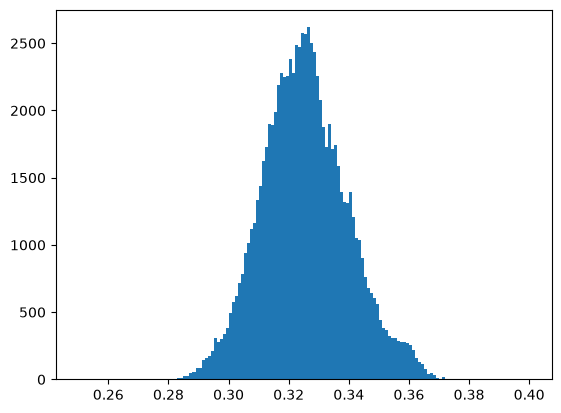

In [21]:
plt.hist(X_train.OBP_162_h, np.linspace(.25,.4,151));

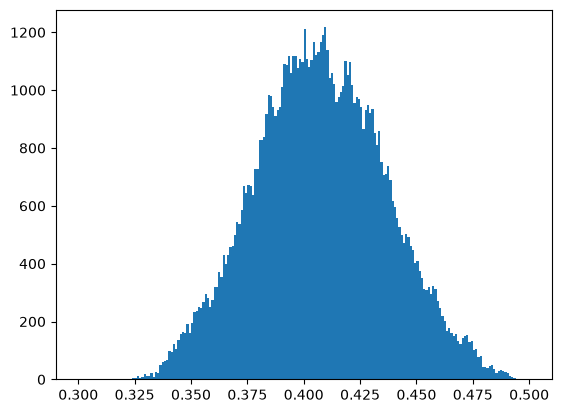

In [22]:
plt.hist(X_train.SLG_162_v, np.linspace(.3,.5,201));

In [23]:
lgbm1 = lgbm.LGBMClassifier(n_estimators=1000, learning_rate=.02, max_depth=2)
lgbm1.fit(X_train, y_train, eval_set=(X_valid, y_valid), eval_metric='logloss', 
          callbacks=[lgbm.early_stopping(stopping_rounds=50), lgbm.log_evaluation(10)])


c:\python\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[LightGBM] [Info] Number of positive: 46303, number of negative: 39651
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000326 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1020
[LightGBM] [Info] Number of data points in the train set: 85954, number of used features: 4
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.538695 -> initscore=0.155091
[LightGBM] [Info] Start training from score 0.155091
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
Training until validation scores don't improve for 50 rounds
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM

,max_depth,2
,learning_rate,0.02
,n_estimators,1000
,boosting_type,'gbdt'
,num_leaves,31
,subsample_for_bin,200000
,objective,None
,class_weight,None
,min_split_gain,0.0
,min_child_weight,0.001
,min_child_samples,20


In [24]:
preds_lgbm = lgbm1.predict_proba(X_test)[:,1]

In [25]:
log_loss(y_test, preds_lgbm), log_loss(y_test, hv_mean*np.ones(len(y_test)))

(np.float64(0.6848928020330081), np.float64(0.6916548080460421))

In [26]:
rd = mli.get_range_dict(X_train)
plot_pts = X_test.sample(3, random_state=42)

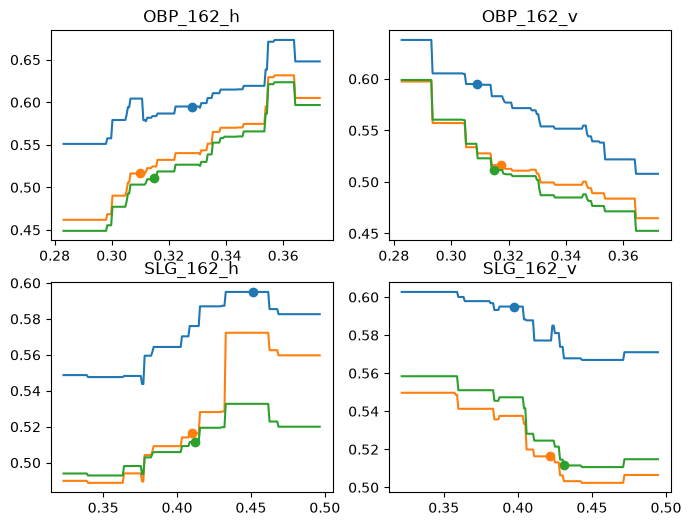

In [27]:
mli.ice_plot(lgbm1, plot_pts, X_test.columns, mli.get_range_dict(X_train), plots_per_row=2)

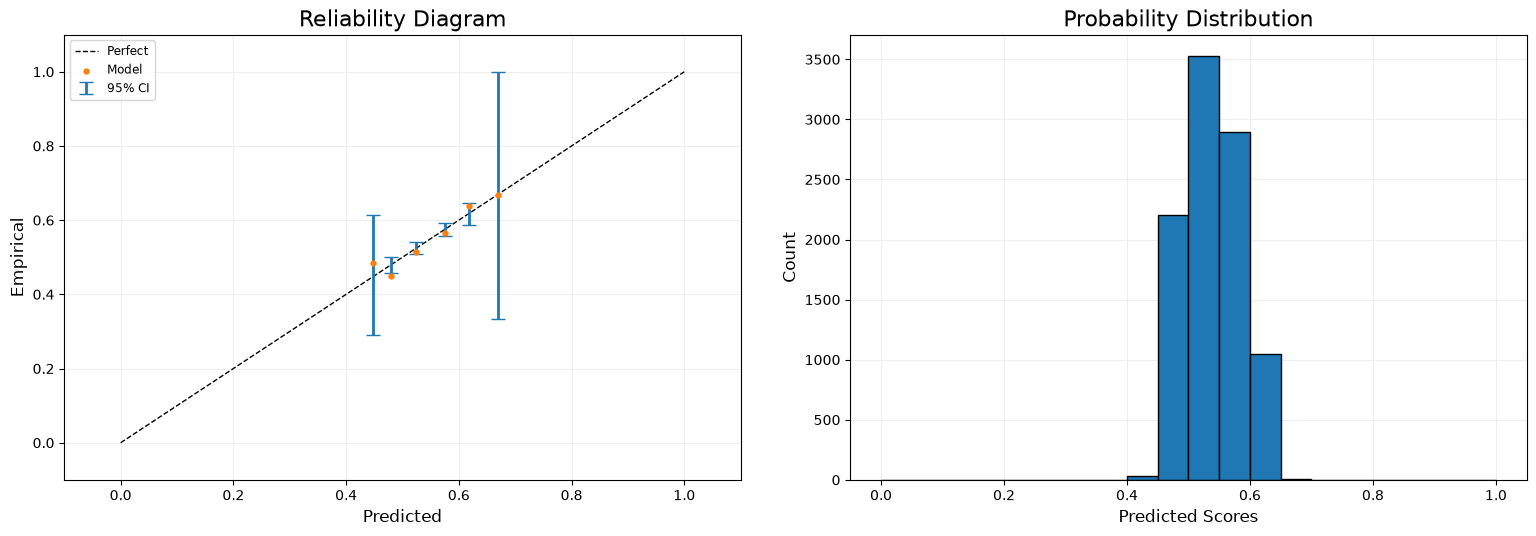

In [28]:
plt.figure(figsize=(16,6))
mli.plot_reliability_diagram(y_test, preds_lgbm, show_histogram=True);

In [ ]:
fc = stb.get_basic_config(X_train, stb.default_config_dict()) # This is the model that runs at a rate to ensure it is accurate

stb1 = stb.StructureBoost(max_depth=3, learning_rate=.02, feature_configs = fc, num_trees=2000)
stb1.fit(X_train, y_train, eval_set=(X_valid, y_valid), early_stop_past_steps=5)

i=0, eval_set_loss = 0.6904403794776431
i=10, eval_set_loss = 0.6891070376863608
i=20, eval_set_loss = 0.6878452650810213
i=30, eval_set_loss = 0.686740504491468
i=40, eval_set_loss = 0.6853374758018274
i=50, eval_set_loss = 0.6843828986082002
i=60, eval_set_loss = 0.6839781736701877
i=70, eval_set_loss = 0.6832170536404234
i=80, eval_set_loss = 0.6826839270236552
i=90, eval_set_loss = 0.6822521453292857
i=100, eval_set_loss = 0.6819186686203933
i=110, eval_set_loss = 0.681493539231452
i=120, eval_set_loss = 0.6812322820201864
i=130, eval_set_loss = 0.6809009550300403
i=140, eval_set_loss = 0.6808496011631582
i=150, eval_set_loss = 0.6806334824689312
i=160, eval_set_loss = 0.6803928030246573
i=170, eval_set_loss = 0.6802286471108069
i=180, eval_set_loss = 0.6801357056378899
i=190, eval_set_loss = 0.6799621521385276
i=200, eval_set_loss = 0.6798231730235369
i=210, eval_set_loss = 0.6797663971936181
i=220, eval_set_loss = 0.6797425779542268
i=230, eval_set_loss = 0.6797922385947894
i=240

In [31]:
preds_stb = stb1.predict(X_test)

In [32]:
log_loss(y_test, preds_stb), log_loss(y_test, hv_mean*np.ones(len(y_test)))

(np.float64(0.6849304624515917), np.float64(0.6916548080460421))

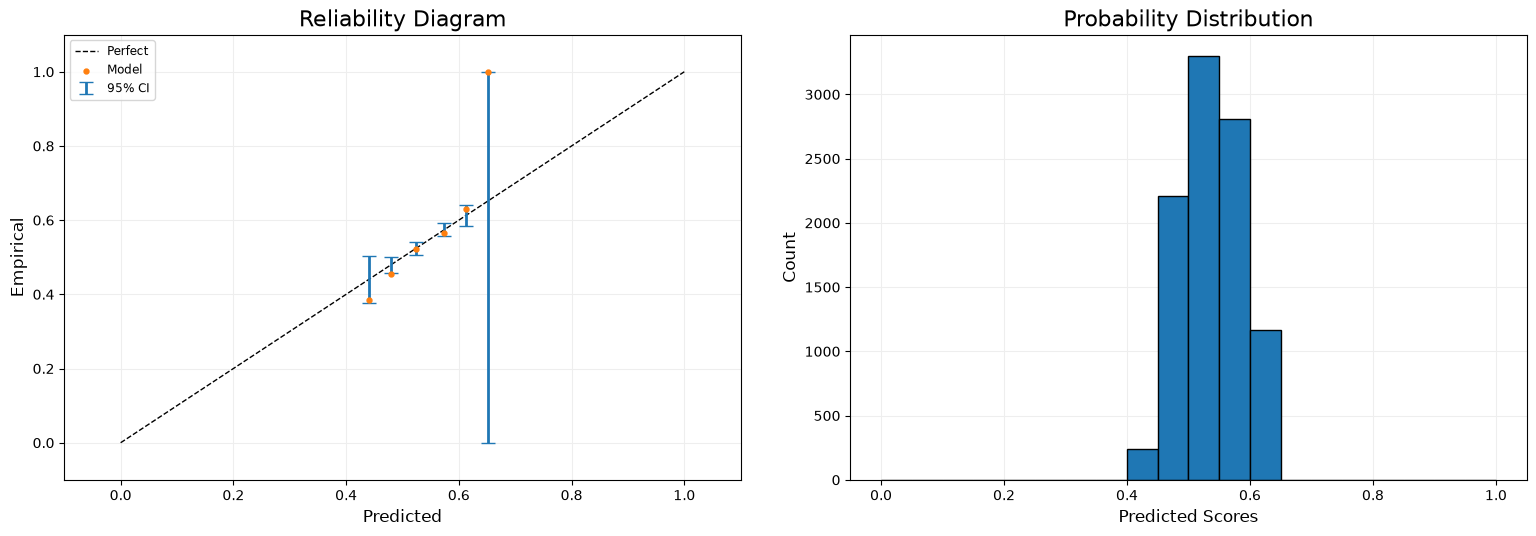

In [33]:
plt.figure(figsize=(16,6))
mli.plot_reliability_diagram(y_test, preds_stb, show_histogram=True);

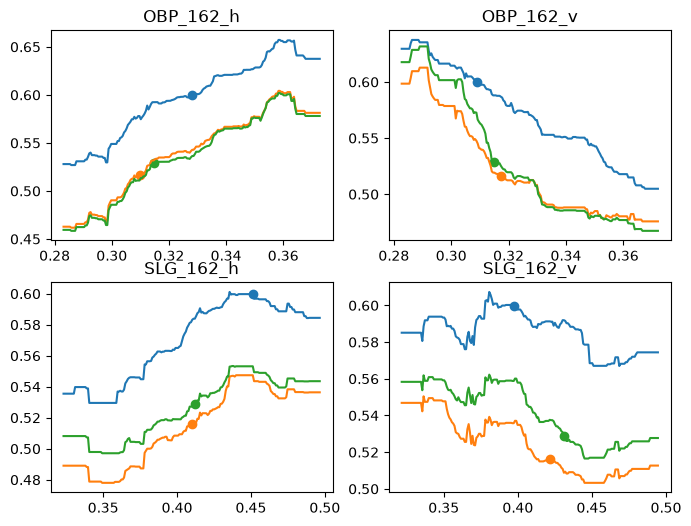

In [34]:
rd= mli.get_range_dict(X_train)
mli.ice_plot(stb1, plot_pts, X_test.columns, rd, plots_per_row=2)